# EDA: readmisión de pacientes con diabetes

Este notebook explora el dataset del Proyecto 2 para tomar las decisiones de limpieza
y confirmar los contratos (`src/schemas.py` y `src/config.py`).

Responde siete preguntas:

1. ¿Qué forma tiene el dataset y coincide con el contrato?
2. ¿Cómo se distribuye el target?
3. ¿Dónde hay nulos y qué columnas no sirven?
4. ¿Los valores de las categorías coinciden con los permitidos en `schemas.py`?
5. ¿Hay pacientes con varios encuentros?
6. ¿Qué encuentros no pueden tener readmisión?
7. ¿Cómo vienen los diagnósticos y cómo se agrupan?

El notebook solo explora y justifica. La limpieza definitiva vive en `src/preprocessing.py`,
que es lo que importa el DAG.

Después de cada sección hay una celda **Conclusión** para escribir, con nuestras palabras,
qué decidimos y por qué. Esas conclusiones van a `docs/decisiones.md`.

## 0. Preparación

In [1]:
import os
import sys
import urllib.request
from pathlib import Path
from typing import get_args

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

# El notebook vive en notebooks/; la raíz del repo es la carpeta de arriba.
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "src"))

import config
import schemas

# El CSV va en data/ (está en .gitignore, no se sube al repo).
DATA_FILE = Path(os.getenv("DATA_FILE", REPO_ROOT / "data" / "Diabetes" / "Diabetes.csv"))
print("Archivo de datos:", DATA_FILE)

Archivo de datos: /home/estudiante/mlops-proyecto2-diabetes/data/Diabetes/Diabetes.csv


In [2]:
# Descarga el dataset del curso si todavía no está en la VM.
DRIVE_ID = "1k5-1caezQ3zWJbKaiMULTGq-3sz6uThC"
URL = f"https://drive.google.com/uc?export=download&id={DRIVE_ID}"

if not DATA_FILE.exists():
    DATA_FILE.parent.mkdir(parents=True, exist_ok=True)
    print("Descargando...")
    urllib.request.urlretrieve(URL, DATA_FILE)

# Si Google Drive devolvió una página web en vez del CSV, avisamos.
with open(DATA_FILE, "rb") as f:
    first_bytes = f.read(200)
if first_bytes.lstrip().startswith(b"<"):
    DATA_FILE.unlink()
    raise RuntimeError(
        "Se descargó una página HTML, no el CSV. Descárgalo manualmente desde el enlace "
        f"del enunciado y déjalo en {DATA_FILE}"
    )
print(f"OK: {DATA_FILE.stat().st_size / 1e6:.1f} MB")

Descargando...


OK: 19.2 MB


In [3]:
# Lectura controlada de nulos:
# - "?" es como el dataset original marca los datos faltantes.
# - keep_default_na=False evita que pandas convierta el texto "None" en nulo.
#   En A1Cresult y max_glu_serum, "None" significa "no se hizo la prueba", que es
#   información real, no un dato faltante.
df = pd.read_csv(DATA_FILE, na_values=["?", ""], keep_default_na=False, low_memory=False)
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 1. Forma del dataset y comparación con el contrato

In [4]:
print(f"Filas: {len(df):,}  |  Columnas: {df.shape[1]}")
print(f"Lotes de {config.BATCH_SIZE:,} registros necesarios: {-(-len(df) // config.BATCH_SIZE)}")
df.dtypes.value_counts()

Filas: 101,766  |  Columnas: 50
Lotes de 15,000 registros necesarios: 7


object    37
int64     13
Name: count, dtype: int64

In [5]:
# ¿Están en el dataset las columnas que el contrato necesita?
needed = schemas.FEATURE_COLUMNS + [config.PATIENT_ID_COLUMN, config.TARGET_SOURCE_COLUMN]
missing = [c for c in needed if c not in df.columns]
extra = [c for c in df.columns if c not in needed]

print("Columnas del contrato que NO están en el dataset:", missing or "ninguna")
print(f"\nColumnas del dataset que el contrato no usa ({len(extra)}):")
print(extra)

Columnas del contrato que NO están en el dataset: ninguna

Columnas del dataset que el contrato no usa (24):
['encounter_id', 'weight', 'payer_code', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


In [6]:
# ¿Hay encuentros duplicados?
if "encounter_id" in df.columns:
    print("encounter_id repetidos:", df["encounter_id"].duplicated().sum())
print("Filas completamente duplicadas:", df.duplicated().sum())

encounter_id repetidos: 0


Filas completamente duplicadas: 0


**Conclusión 1:** _(escribir después de correr)_

## 2. Target

In [7]:
target_counts = df[config.TARGET_SOURCE_COLUMN].value_counts(dropna=False)
target_pct = (target_counts / len(df) * 100).round(2)
display(pd.DataFrame({"registros": target_counts, "%": target_pct}))

positive_rate = (df[config.TARGET_SOURCE_COLUMN] == config.POSITIVE_CLASS_VALUE).mean()
print(f"Clase positiva ({config.POSITIVE_CLASS_VALUE!r}): {positive_rate:.2%} de los registros")
print(f"Por cada readmisión <30 hay {(1 - positive_rate) / positive_rate:.1f} que no lo son")

,registros,%
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


Clase positiva ('<30'): 11.16% de los registros
Por cada readmisión <30 hay 8.0 que no lo son


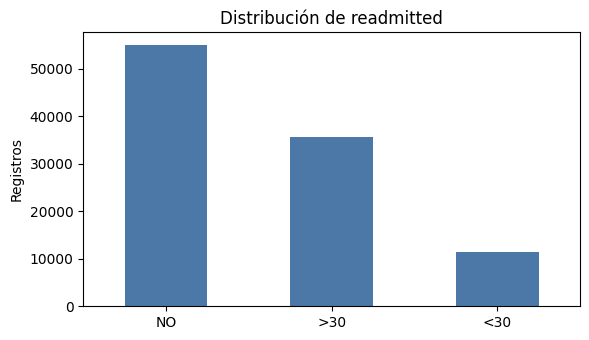

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
target_counts.plot.bar(ax=ax, color="#4C78A8")
ax.set_title("Distribución de readmitted")
ax.set_xlabel("")
ax.set_ylabel("Registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Con un desbalance así, *accuracy* engaña: un modelo que siempre dice "no se readmite"
tiene accuracy alta y no detecta a nadie. Por eso la métrica principal debe mirar la clase
positiva (recall, F2 o PR-AUC).

**Conclusión 2:** _(escribir: target binario sí/no, porcentaje de positivos y métrica elegida)_

## 3. Nulos, columnas constantes y columnas inútiles

In [9]:
nulls = df.isna().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
null_table = pd.DataFrame({"nulos": nulls, "%": (nulls / len(df) * 100).round(2)})
null_table

,nulos,%
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


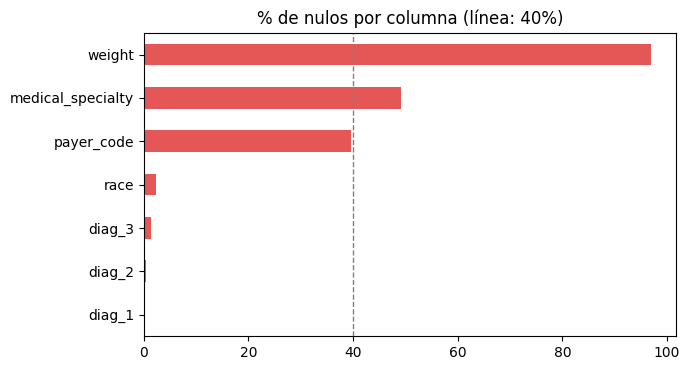

In [10]:
if len(null_table):
    fig, ax = plt.subplots(figsize=(7, 0.4 * len(null_table) + 1))
    null_table["%"].sort_values().plot.barh(ax=ax, color="#E45756")
    ax.axvline(40, color="gray", linestyle="--", linewidth=1)
    ax.set_title("% de nulos por columna (línea: 40%)")
    plt.tight_layout()
    plt.show()

In [11]:
# Columnas con un solo valor (no aportan nada) o casi constantes (>99% el mismo valor).
summary = []
for col in df.columns:
    top_share = df[col].value_counts(normalize=True, dropna=False).iloc[0]
    summary.append((col, df[col].nunique(dropna=False), round(top_share * 100, 2)))
const = pd.DataFrame(summary, columns=["columna", "valores_distintos", "% valor_más_común"])
const = const[const["% valor_más_común"] >= 99].sort_values("% valor_más_común", ascending=False)
const

,columna,valores_distintos,% valor_más_común
29,acetohexamide,2,100.00
37,troglitazone,2,100.00
46,metformin-pioglitazone,2,100.00
44,glimepiride-pioglitazone,2,100.00
45,metformin-rosiglitazone,2,100.00
40,citoglipton,1,100.00
39,examide,1,100.00
43,glipizide-metformin,2,99.99
32,tolbutamide,2,99.98
38,tolazamide,3,99.96


In [12]:
# Columnas candidatas a eliminar (regla: >40% nulos o >99% un solo valor).
# Los identificadores no son features: sirven para trazar y para el split.
high_null = null_table.index[null_table["%"] > 40].tolist()
near_constant = const["columna"].tolist()
identifiers = [c for c in ["encounter_id", "patient_nbr"] if c in df.columns]

print("Más de 40% nulos:", high_null)
print("Casi constantes:", near_constant)
print("Identificadores (no son features):", identifiers)

Más de 40% nulos: ['weight', 'medical_specialty']
Casi constantes: ['acetohexamide', 'troglitazone', 'metformin-pioglitazone', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'citoglipton', 'examide', 'glipizide-metformin', 'tolbutamide', 'tolazamide', 'miglitol', 'chlorpropamide', 'acarbose', 'nateglinide', 'glyburide-metformin']
Identificadores (no son features): ['encounter_id', 'patient_nbr']


**Conclusión 3:** _(escribir: qué columnas salen y por qué; cómo se tratan los nulos que
quedan, por ejemplo race → "Unknown" y medical_specialty → "Unknown")_

## 4. Valores de las categorías frente al contrato

`schemas.py` define qué valores acepta la API en cada campo. Aquí comparamos esos valores
con los que realmente trae el dataset. `diag_*` y `medical_specialty` se omiten porque en el
contrato van **agrupados** (se revisan en la sección 7).

In [13]:
grouped_in_contract = {"diag_1", "diag_2", "diag_3", "medical_specialty"}
rows = []
for name, field in schemas.PatientFeatures.model_fields.items():
    allowed = get_args(field.annotation)
    if not allowed or name in grouped_in_contract or name not in df.columns:
        continue
    real = set(df[name].dropna().astype(str).unique())
    allowed = {str(v) for v in allowed}
    rows.append({
        "campo": name,
        "en datos y NO en contrato": sorted(real - allowed),
        "en contrato y NO en datos": sorted(allowed - real),
        "nulos": int(df[name].isna().sum()),
    })
cat_check = pd.DataFrame(rows)
cat_check

,campo,en datos y NO en contrato,en contrato y NO en datos,nulos
0,race,[],[Unknown],2273
1,gender,[Unknown/Invalid],[],0
2,age,[],[],0
3,max_glu_serum,[],[],0
4,A1Cresult,[],[],0
5,insulin,[],[],0
6,metformin,[],[],0
7,change,[],[],0
8,diabetesMed,[],[],0


In [14]:
# Lo mismo para los campos numéricos: ¿los límites ge/le del contrato rechazarían datos reales?
rows = []
for name, field in schemas.PatientFeatures.model_fields.items():
    if name not in schemas.NUMERIC_FEATURES or name not in df.columns:
        continue
    lo = next((m.ge for m in field.metadata if hasattr(m, "ge")), None)
    hi = next((m.le for m in field.metadata if hasattr(m, "le")), None)
    col = pd.to_numeric(df[name], errors="coerce")
    rows.append({
        "campo": name, "mín real": col.min(), "máx real": col.max(),
        "contrato": f"[{lo}, {hi}]",
        "fuera de rango": int(((col < lo) | (col > hi)).sum()),
    })
pd.DataFrame(rows)

,campo,mín real,máx real,contrato,fuera de rango
0,admission_type_id,1,8,"[1, 8]",0
1,discharge_disposition_id,1,28,"[1, 29]",0
2,admission_source_id,1,25,"[1, 26]",0
3,time_in_hospital,1,14,"[1, 14]",0
4,num_lab_procedures,1,132,"[0, 150]",0
5,num_procedures,0,6,"[0, 10]",0
6,num_medications,1,81,"[0, 100]",0
7,number_diagnoses,1,16,"[1, 20]",0
8,number_outpatient,0,42,"[0, 50]",0
9,number_emergency,0,76,"[0, 80]",0


In [15]:
# Distribución de cada categórica del contrato, para ver cuáles valores son raros.
for name in ["race", "gender", "age", "max_glu_serum", "A1Cresult", "insulin", "metformin", "change", "diabetesMed"]:
    if name in df.columns:
        print(f"--- {name}")
        print(df[name].value_counts(dropna=False).to_string(), "\n")

--- race
race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641 

--- gender
gender
Female             54708
Male               47055
Unknown/Invalid        3 

--- age
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161 

--- max_glu_serum
max_glu_serum
None    96420
Norm     2597
>200     1485
>300     1264 

--- A1Cresult
A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812 

--- insulin
insulin
No        47383
Steady    30849
Down      12218
Up        11316 

--- metformin
metformin
No        81778
Steady    18346
Up         1067
Down        575 

--- change
change
No    54755
Ch    47011 

--- diabetesMed
diabetesMed
Yes    78363
No     23403 



**Conclusión 4:** _(escribir: qué valores hay que agregar o quitar en `schemas.py`, y qué
hacer con valores raros, por ejemplo gender "Unknown/Invalid")_

## 5. Pacientes con varios encuentros

In [16]:
pid = config.PATIENT_ID_COLUMN
per_patient = df.groupby(pid).size()
repeated = per_patient[per_patient > 1]

print(f"Encuentros: {len(df):,}")
print(f"Pacientes distintos: {per_patient.size:,}")
print(f"Pacientes con más de un encuentro: {repeated.size:,} ({repeated.size / per_patient.size:.1%})")
print(f"Encuentros que pertenecen a esos pacientes: {repeated.sum():,} ({repeated.sum() / len(df):.1%})")
print(f"Máximo de encuentros de un mismo paciente: {per_patient.max()}")

Encuentros: 101,766
Pacientes distintos: 71,518
Pacientes con más de un encuentro: 16,773 (23.5%)
Encuentros que pertenecen a esos pacientes: 47,021 (46.2%)
Máximo de encuentros de un mismo paciente: 40


Si un paciente aparece en entrenamiento y en prueba, el modelo "ya lo conoce" y las métricas
salen infladas. Por eso el split se hace **por paciente**: todos los encuentros de un paciente
caen en el mismo conjunto. Además se hace con un hash del `patient_nbr` y no al azar, para
que en cada ejecución del DAG un paciente quede siempre en el mismo conjunto, aunque lleguen
lotes nuevos.

In [17]:
# Prueba del split determinista por hash: proporciones obtenidas.
import hashlib

def split_of(patient_id) -> str:
    h = hashlib.md5(f"{config.SPLIT_SALT}-{patient_id}".encode()).hexdigest()
    u = int(h[:8], 16) / 0xFFFFFFFF  # número entre 0 y 1, siempre el mismo para ese paciente
    if u < config.TRAIN_FRACTION:
        return "train"
    if u < config.TRAIN_FRACTION + config.VAL_FRACTION:
        return "val"
    return "test"

split = df[pid].map(split_of)
positive = df[config.TARGET_SOURCE_COLUMN] == config.POSITIVE_CLASS_VALUE
pd.DataFrame({
    "encuentros": split.value_counts(),
    "% encuentros": (split.value_counts(normalize=True) * 100).round(1),
    "% positivos": (positive.groupby(split).mean() * 100).round(2),
})

,encuentros,% encuentros,% positivos
patient_nbr,,,
test,15280,15.0,11.37
train,71064,69.8,11.09
val,15422,15.2,11.26


**Conclusión 5:** _(escribir: el split por paciente queda balanceado en proporción y en % de positivos)_

## 6. Encuentros que no pueden tener readmisión

En el dataset original, `discharge_disposition_id` 11, 19, 20 y 21 significan que el paciente
falleció, y 13 y 14 que fue a cuidados paliativos (hospicio). Esos pacientes no pueden volver
a ingresar, así que dejarlos enseñaría al modelo algo falso.

In [18]:
EXPIRED_OR_HOSPICE = [11, 13, 14, 19, 20, 21]

col = pd.to_numeric(df["discharge_disposition_id"], errors="coerce")
excluded = col.isin(EXPIRED_OR_HOSPICE)
print(f"Encuentros a excluir: {excluded.sum():,} ({excluded.mean():.2%})")

pd.DataFrame({
    "encuentros": col[excluded].value_counts(),
    "% readmitidos <30": (positive[excluded].groupby(col[excluded]).mean() * 100).round(2),
}).sort_index()

Encuentros a excluir: 2,423 (2.38%)


,encuentros,% readmitidos <30
discharge_disposition_id,,
11,1642,0.00
13,399,4.76
14,372,6.45
19,8,0.00
20,2,0.00


**Conclusión 6:** _(escribir: cuántos se excluyen y por qué)_

## 7. Diagnósticos (ICD-9) y especialidad médica

In [19]:
# ¿Cómo vienen los códigos? Numéricos (428, 250.83), con V o E al inicio, o nulos.
def code_kind(value) -> str:
    if pd.isna(value):
        return "nulo"
    s = str(value).strip().upper()
    if s.startswith("V"):
        return "V (factores de salud)"
    if s.startswith("E"):
        return "E (causas externas)"
    try:
        float(s)
        return "numérico"
    except ValueError:
        return "otro"

pd.DataFrame({d: df[d].map(code_kind).value_counts() for d in ["diag_1", "diag_2", "diag_3"]}).fillna(0).astype(int)

,diag_1,diag_2,diag_3
E (causas externas),1,731,1244
V (factores de salud),1644,1805,3814
nulo,21,358,1423
numérico,100100,98872,95285


Hay cientos de códigos distintos, demasiados para usarlos directo. Los agrupamos en las 9
categorías de Strack et al. (2014), el artículo que publicó este dataset. Esta función es el
prototipo de la que irá en `src/preprocessing.py`.

In [20]:
def group_icd9(value) -> str:
    if pd.isna(value):
        return "Missing"
    s = str(value).strip().upper()
    if s.startswith(("V", "E")):
        return "Other"
    try:
        c = float(s)
    except ValueError:
        return "Other"
    if 390 <= c <= 459 or int(c) == 785:
        return "Circulatory"
    if 460 <= c <= 519 or int(c) == 786:
        return "Respiratory"
    if 520 <= c <= 579 or int(c) == 787:
        return "Digestive"
    if int(c) == 250:
        return "Diabetes"
    if 800 <= c <= 999:
        return "Injury"
    if 710 <= c <= 739:
        return "Musculoskeletal"
    if 580 <= c <= 629 or int(c) == 788:
        return "Genitourinary"
    if 140 <= c <= 239:
        return "Neoplasms"
    return "Other"

diag_groups = pd.DataFrame({d: df[d].map(group_icd9).value_counts() for d in ["diag_1", "diag_2", "diag_3"]}).fillna(0).astype(int)
diag_groups

,diag_1,diag_2,diag_3
Circulatory,30437,31881,30306
Diabetes,8757,12794,17157
Digestive,9475,4170,3930
Genitourinary,5117,8376,6680
Injury,6974,2428,1946
Missing,21,358,1423
Musculoskeletal,4957,1764,1915
Neoplasms,3433,2547,1856
Other,18172,26553,29195
Respiratory,14423,10895,7358


In [21]:
# ¿El grupo del diagnóstico principal cambia la tasa de readmisión?
g = df["diag_1"].map(group_icd9)
(positive.groupby(g).mean() * 100).round(2).sort_values(ascending=False).rename("% readmitidos <30")

diag_1
Missing            23.81
Diabetes           12.98
Injury             12.25
Other              11.48
Circulatory        11.45
Genitourinary      10.85
Digestive          10.71
Neoplasms          10.08
Respiratory         9.73
Musculoskeletal     9.50
Name: % readmitidos <30, dtype: float64

In [22]:
# Especialidad médica: muchas categorías y muchos nulos.
spec = df["medical_specialty"].fillna("Unknown")
print(f"Especialidades distintas: {spec.nunique()}")
spec.value_counts().head(15)

Especialidades distintas: 73


medical_specialty
Unknown                            49949
InternalMedicine                   14635
Emergency/Trauma                    7565
Family/GeneralPractice              7440
Cardiology                          5352
Surgery-General                     3099
Nephrology                          1613
Orthopedics                         1400
Orthopedics-Reconstructive          1233
Radiologist                         1140
Pulmonology                          871
Psychiatry                           854
Urology                              685
ObstetricsandGynecology              671
Surgery-Cardiovascular/Thoracic      652
Name: count, dtype: int64

**Conclusión 7:** _(escribir: agrupación de diagnósticos, qué hacer con "Missing" —agregarlo al
contrato o mandarlo a "Other"— y cómo se agrupa medical_specialty)_

## 8. Variables que más se relacionan con el target

Una mirada rápida para el video: ¿qué variables parecen anticipar una readmisión?

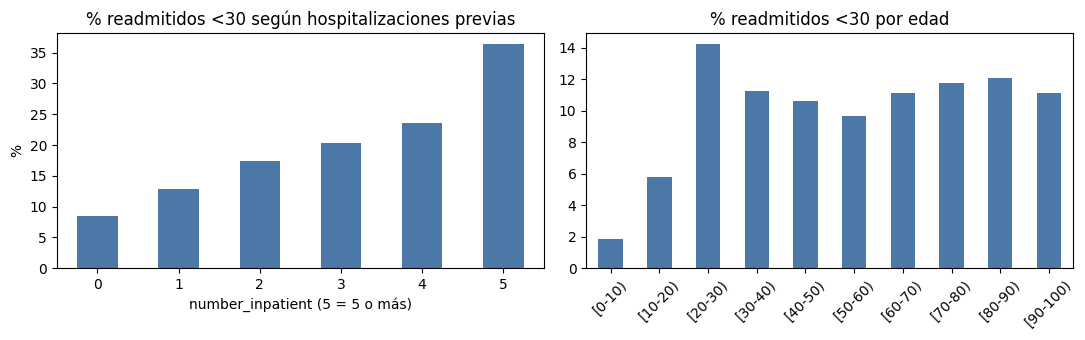

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

inp = pd.to_numeric(df["number_inpatient"], errors="coerce").clip(upper=5)
(positive.groupby(inp).mean() * 100).plot.bar(ax=axes[0], color="#4C78A8")
axes[0].set_title("% readmitidos <30 según hospitalizaciones previas")
axes[0].set_xlabel("number_inpatient (5 = 5 o más)")
axes[0].set_ylabel("%")

(positive.groupby(df["age"]).mean() * 100).plot.bar(ax=axes[1], color="#4C78A8")
axes[1].set_title("% readmitidos <30 por edad")
axes[1].set_xlabel("")

for ax in axes:
    ax.tick_params(axis="x", rotation=0 if ax is axes[0] else 45)
plt.tight_layout()
plt.show()

In [24]:
# Correlación de las numéricas con el target binario.
numeric = df[schemas.NUMERIC_FEATURES].apply(pd.to_numeric, errors="coerce")
numeric.corrwith(positive.astype(int)).sort_values(ascending=False).round(3).rename("correlación con <30")

number_inpatient            0.165
number_emergency            0.061
discharge_disposition_id    0.051
number_diagnoses            0.050
time_in_hospital            0.044
num_medications             0.038
num_lab_procedures          0.020
number_outpatient           0.019
admission_source_id         0.006
admission_type_id          -0.012
num_procedures             -0.012
Name: correlación con <30, dtype: float64

**Conclusión 8:** _(escribir: qué variables destacan)_

## 9. Resumen para `docs/decisiones.md`

Esta celda junta los números de arriba. Revísalos, ajusta lo que decidan y copia las líneas
a `docs/decisiones.md`.

In [25]:
from datetime import date
MONTHS = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
today = f"{date.today().day}-{MONTHS[date.today().month - 1]}"

# Las features del contrato no se eliminan aunque tengan muchos nulos:
# sus nulos se convierten en una categoría ("Unknown").
candidates = set(high_null + near_constant)
drop_cols = sorted(candidates - set(schemas.FEATURE_COLUMNS))
kept_with_nulls = sorted(candidates & set(schemas.FEATURE_COLUMNS))
lines = [
    f"{today}. Dataset: {len(df):,} encuentros, {per_patient.size:,} pacientes, {df.shape[1]} columnas. "
    f"Se carga en {-(-len(df) // config.BATCH_SIZE)} lotes de máximo {config.BATCH_SIZE:,}.",
    f"{today}. Target binario: readmitted == '{config.POSITIVE_CLASS_VALUE}' (positivos: {positive_rate:.1%}). "
    "Accuracy no sirve por el desbalance.",
    f"{today}. Se eliminan columnas con >40% nulos o >99% un solo valor: {', '.join(drop_cols) or 'ninguna'}.",
    f"{today}. Se conservan aunque tengan muchos nulos (nulo -> 'Unknown'): {', '.join(kept_with_nulls) or 'ninguna'}.",
    f"{today}. encounter_id y patient_nbr no son features; patient_nbr se usa para el split.",
    f"{today}. Se excluyen {excluded.sum():,} encuentros de fallecidos u hospicio (discharge_disposition_id {EXPIRED_OR_HOSPICE}).",
    f"{today}. Split determinista por hash de patient_nbr: {config.TRAIN_FRACTION:.0%}/{config.VAL_FRACTION:.0%}/{config.TEST_FRACTION:.0%}; "
    f"{repeated.size:,} pacientes tienen varios encuentros y no pueden quedar en dos conjuntos.",
    f"{today}. Diagnósticos ICD-9 agrupados en 9 categorías (Strack et al., 2014).",
]
if missing:
    lines.append(f"{today}. ATENCIÓN: columnas del contrato que no existen en el dataset: {missing}.")
print("\n".join(lines))

29-oct. Dataset: 101,766 encuentros, 71,518 pacientes, 50 columnas. Se carga en 7 lotes de máximo 15,000.
29-oct. Target binario: readmitted == '<30' (positivos: 11.2%). Accuracy no sirve por el desbalance.
29-oct. Se eliminan columnas con >40% nulos o >99% un solo valor: acarbose, acetohexamide, chlorpropamide, citoglipton, examide, glimepiride-pioglitazone, glipizide-metformin, glyburide-metformin, metformin-pioglitazone, metformin-rosiglitazone, miglitol, nateglinide, tolazamide, tolbutamide, troglitazone, weight.
29-oct. Se conservan aunque tengan muchos nulos (nulo -> 'Unknown'): medical_specialty.
29-oct. encounter_id y patient_nbr no son features; patient_nbr se usa para el split.
29-oct. Se excluyen 2,423 encuentros de fallecidos u hospicio (discharge_disposition_id [11, 13, 14, 19, 20, 21]).
29-oct. Split determinista por hash de patient_nbr: 70%/15%/15%; 16,773 pacientes tienen varios encuentros y no pueden quedar en dos conjuntos.
29-oct. Diagnósticos ICD-9 agrupados en 9 ca